## ![](https://ga-dash.s3.amazonaws.com/production/assets/logo-9f88ae6c9c3871690e33280fcf557f33.png) Convolutional Neural Networks

**By the end of the lesson, you should be able to:**
- Identify use cases for convolutional neural networks and when they are superior to other neural networks.
- Describe convolutional and pooling layers.
- Define padding and filters.
- Fit CNNs in Keras.

In [1]:
# Import libraries and modules
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, Flatten, Conv2D, MaxPooling2D
from tensorflow.keras.datasets import mnist, cifar10

2024-12-09 19:16:05.731517: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
# Load pre-shuffled MNIST data into train and test sets
(X_train, y_train), (X_test, y_test) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [3]:
# 3 dimensional data?!
X_train.shape

(60000, 28, 28)

In [4]:
# Check one value of X_train.
X_train[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  

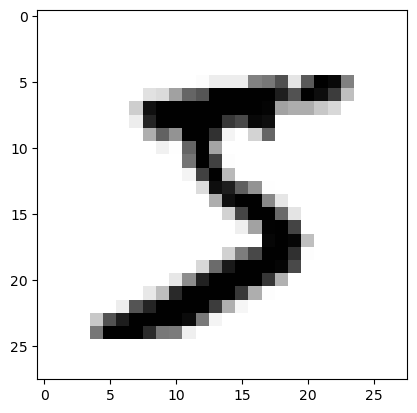

In [5]:
plt.imshow(X_train[0], cmap='binary');

In [6]:
# It's typical to minmax scale data like this. Fortunately, it's just as easy as
# dividing by the maximal value
X_train = X_train / 255
X_test = X_test / 255

In [7]:
# Image data are actually 3-dimensional, where the 3rd data is reserved for 
# the RGB color channel. Our data is only black and white, but we still need to add
# a 3rd dimension
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

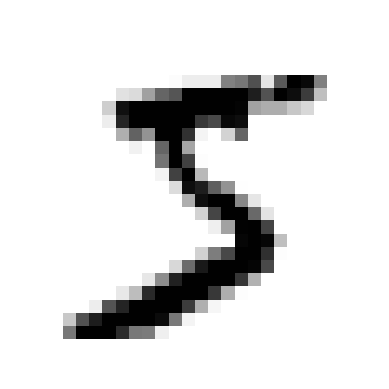

In [8]:
# See? Same.
plt.axis('off')
plt.imshow(X_train[0], cmap='binary');

In [13]:
# Let's jump right in! We'll fit a CNN
# Recall an earlier benchmark: In our SVM lesson, we used
# a simpler version of this data and achieved a test score of 98.8%

model = Sequential()

# Add the Input layer as the first layer.
model.add(Input(shape=(28,28,1)))

# Make a convolutional layer with 32 filters.
model.add(Conv2D(32, 3, activation='relu'))

# MaxPool the results (basically a requirement)
model.add(MaxPooling2D(2))

# Let's add another convolution block
model.add(Conv2D(64, 3, activation='relu'))
model.add(MaxPooling2D(2))

# Finally, flatten the output and make a predictions through a dense layer.
model.add(Flatten())
model.add(Dense(10, activation='softmax'))

In [14]:
# Look at them layers!
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │        16,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,826 (136.04 KB)

 Trainable params: 34,826 (136.04 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
# Compile
model.compile(
    loss='sparse_categorical_crossentropy', 
    optimizer='rmsprop',
    metrics=['acc']
)

In [16]:
# Fit!
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    batch_size=128,
    epochs=10
)

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 27s 55ms/step - acc: 0.8468 - loss: 0.5227 - val_acc: 0.9738 - val_loss: 0.0813
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 28s 60ms/step - acc: 0.9746 - loss: 0.0805 - val_acc: 0.9791 - val_loss: 0.0662
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 26s 56ms/step - acc: 0.9825 - loss: 0.0565 - val_acc: 0.9844 - val_loss: 0.0436
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 29s 62ms/step - acc: 0.9868 - loss: 0.0441 - val_acc: 0.9799 - val_loss: 0.0631
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 26s 56ms/step - acc: 0.9885 - loss: 0.0380 - val_acc: 0.9863 - val_loss: 0.0400
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 26s 55ms/step - acc: 0.9904 - loss: 0.0337 - val_acc: 0.9874 - val_loss: 0.0352
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 32s 67ms/step - acc: 0.9915 - loss: 0.0287 - val_acc: 0.9866 - val_loss: 0.0419
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 29s 61ms/step - acc: 0.9933 - loss: 0.0247 - val_acc: 0.9882 - val_loss: 0.0325
Epoch 9/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 

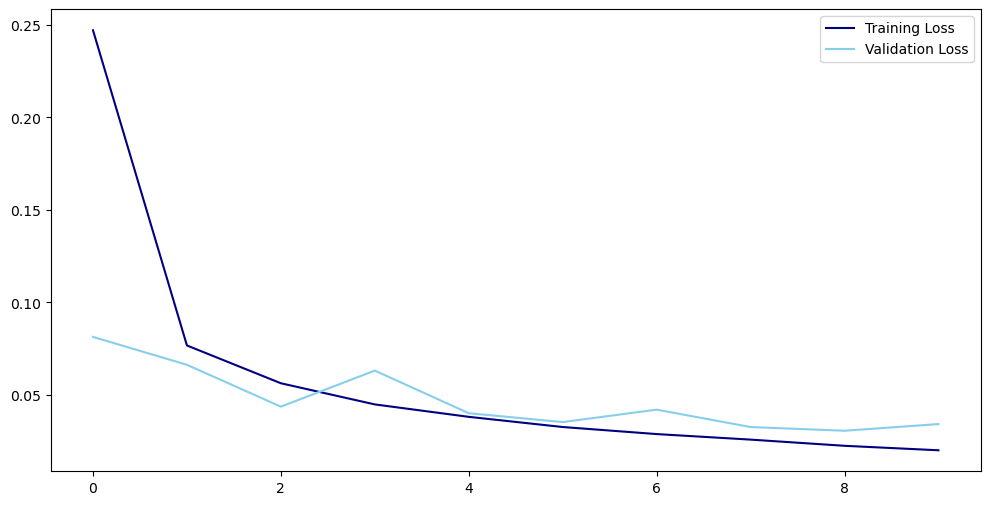

In [17]:
# Check out the plot of loss vs epoch. How's our model?
plt.figure(figsize=(12, 6))
plt.plot(history.history['loss'], c='navy', label='Training Loss')
plt.plot(history.history['val_loss'], c='skyblue', label='Validation Loss')
plt.legend();

In [18]:
# What's our model accuracy?
model.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - acc: 0.9863 - loss: 0.0434


[0.034141432493925095, 0.9889000058174133]

In [19]:
# Generate predicted probabilities from our test set --> convert to predictions.
# To return the ARGUMENT with the MAXIMUM probability, we use NumPy's argmax.
y_pred = np.argmax(model.predict(X_test), axis=1)
y_pred

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


array([7, 2, 1, ..., 4, 5, 6])

In [20]:
# What are our true values?
y_test

array([7, 2, 1, ..., 4, 5, 6], dtype=uint8)

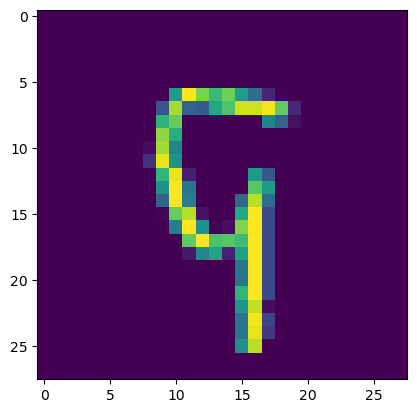

We thought = 5, but really 9


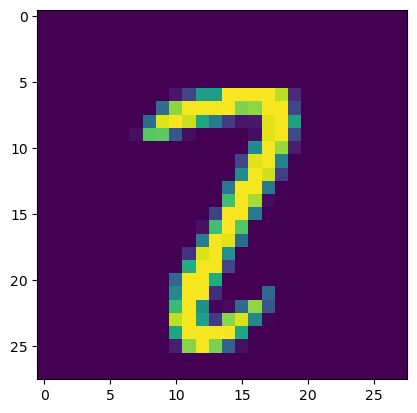

We thought = 7, but really 2


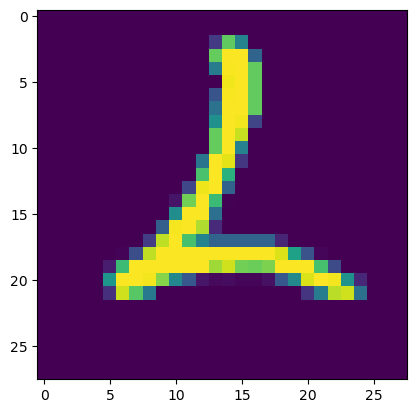

We thought = 1, but really 2


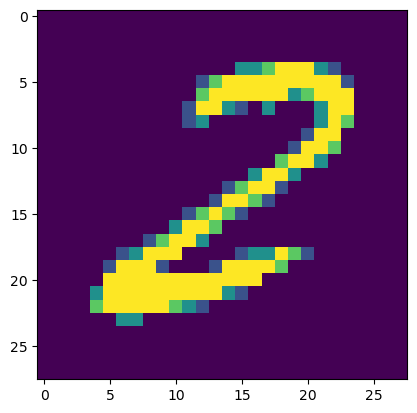

We thought = 8, but really 2


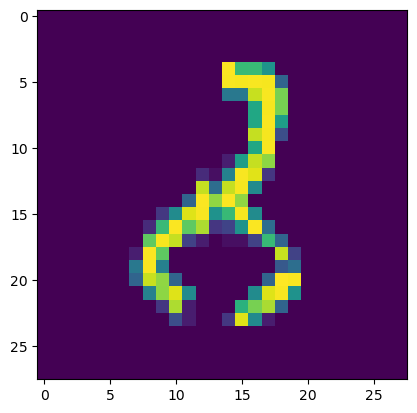

We thought = 2, but really 8


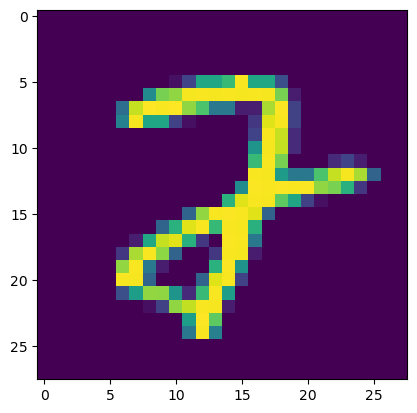

We thought = 7, but really 2


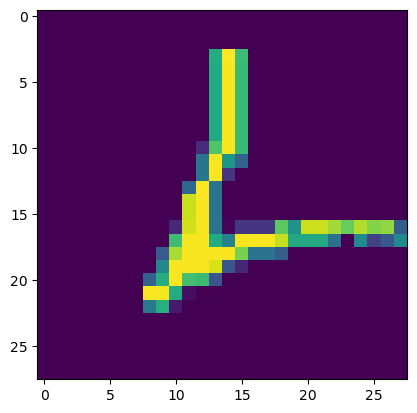

We thought = 4, but really 2


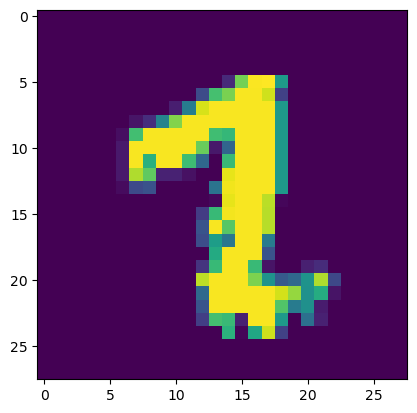

We thought = 1, but really 2


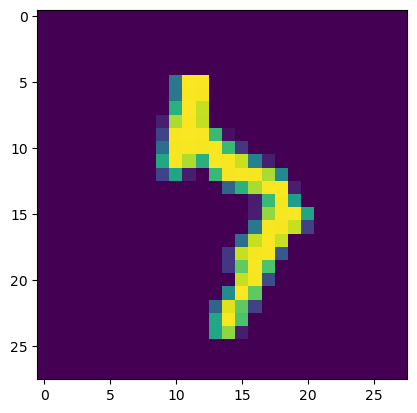

We thought = 4, but really 7


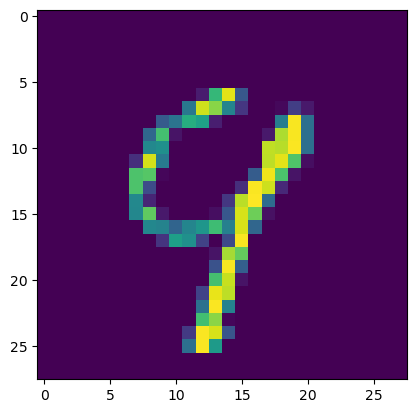

We thought = 7, but really 9


In [21]:
# Store indices where our predictions don't match the truth.
wrong_ix = np.where(y_pred != y_test)[0]

# For each of the first few indices...
for i in wrong_ix[:10]:
    
    # Show the image.
    plt.clf()
    plt.imshow(X_test[i])
    plt.show()
    
    # Write what the predicted value and the true value were.
    pred = y_pred[i]
    truth = y_test[i]
    print(f'We thought = {pred}, but really {truth}')

# Let's Try Another Dataset — this time, in color!
We'll use the famous CIFAR10 dataset. You can read a little about it [here](https://keras.io/api/datasets/cifar10/).

In [22]:
# Downloading about 170.5 million numbers.
(X_train, y_train), (X_test, y_test) = cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


In [23]:
# How much training data do we have?
X_train.shape

(50000, 32, 32, 3)

In [24]:
# And what about y?
y_train.shape

(50000, 1)

In [25]:
# The red channel of image 0
X_train[0, :, :, 0]

array([[ 59,  43,  50, ..., 158, 152, 148],
       [ 16,   0,  18, ..., 123, 119, 122],
       [ 25,  16,  49, ..., 118, 120, 109],
       ...,
       [208, 201, 198, ..., 160,  56,  53],
       [180, 173, 186, ..., 184,  97,  83],
       [177, 168, 179, ..., 216, 151, 123]], dtype=uint8)

Category: [6]


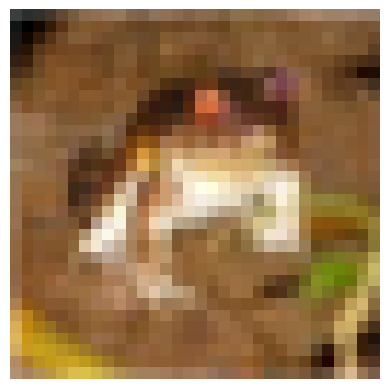

In [27]:
# Nice... frog?
i = 0
print(f"Category: {y_train[i]}")
plt.axis('off')
plt.imshow(X_train[i]);

In [26]:
# Let's scale our Xs again.
X_train = X_train / 255
X_test = X_test / 255

# Confirm we did this right:
X_train[0, :, :, 0]

array([[0.23137255, 0.16862745, 0.19607843, ..., 0.61960784, 0.59607843,
        0.58039216],
       [0.0627451 , 0.        , 0.07058824, ..., 0.48235294, 0.46666667,
        0.47843137],
       [0.09803922, 0.0627451 , 0.19215686, ..., 0.4627451 , 0.47058824,
        0.42745098],
       ...,
       [0.81568627, 0.78823529, 0.77647059, ..., 0.62745098, 0.21960784,
        0.20784314],
       [0.70588235, 0.67843137, 0.72941176, ..., 0.72156863, 0.38039216,
        0.3254902 ],
       [0.69411765, 0.65882353, 0.70196078, ..., 0.84705882, 0.59215686,
        0.48235294]])

In [28]:
# Let's fit a model! Gotta be a big one.
# CNN with the following specs:
# - A convolution block that makes 64 3x3 filters
# - A convolution block that makes 128 3x3 filters
# - ...and is then flattened...
# - A final dense layer with 64 nodes
model = Sequential()

# Add the Input layer as the first layer.
model.add(Input(shape=(32, 32, 3)))

# First convolutional layer, then pool.
model.add(Conv2D(64, 3, activation='relu'))
model.add(MaxPooling2D(2))

# Second convolutional layer, then pool.
model.add(Conv2D(128, 3, activation='relu'))
model.add(MaxPooling2D(2))

# Flatten, in order to pass into our densely-connected layers.
model.add(Flatten())

# Densely-connected hidden layer.
model.add(Dense(64, activation='relu'))

# Output layer.
model.add(Dense(10, activation='softmax'))

In [29]:
# What does our model look like?
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 30, 30, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 15, 15, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 13, 13, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │       294,976 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 371,274 (1.42 MB)

 Trainable params: 371,274 (1.42 MB)

 Non-trainable params: 0 (0.00 B)

In [30]:
# Compile it.
model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='rmsprop',
    metrics=['acc']
)

In [31]:
# Fit it, storing history.
# This should take about 15 minutes to run, beginning to end.
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    batch_size=32,
    epochs=10
)

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 78s 49ms/step - acc: 0.3815 - loss: 1.7040 - val_acc: 0.6036 - val_loss: 1.1176
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 88s 56ms/step - acc: 0.6216 - loss: 1.0877 - val_acc: 0.6398 - val_loss: 1.0237
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 76s 49ms/step - acc: 0.6859 - loss: 0.9050 - val_acc: 0.6579 - val_loss: 0.9964
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 83s 53ms/step - acc: 0.7277 - loss: 0.7913 - val_acc: 0.6842 - val_loss: 0.9354
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 83s 53ms/step - acc: 0.7570 - loss: 0.7041 - val_acc: 0.6879 - val_loss: 0.9532
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 81s 52ms/step - acc: 0.7838 - loss: 0.6235 - val_acc: 0.6979 - val_loss: 0.9454
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 82s 53ms/step - acc: 0.8089 - loss: 0.5562 - val_acc: 0.7085 - val_loss: 0.9386
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 81s 52ms/step - acc: 0.8341 - loss: 0.4890 - val_acc: 0.7055 - val_loss: 0.9863
Epoch 9/10
1563/1563 ━━━

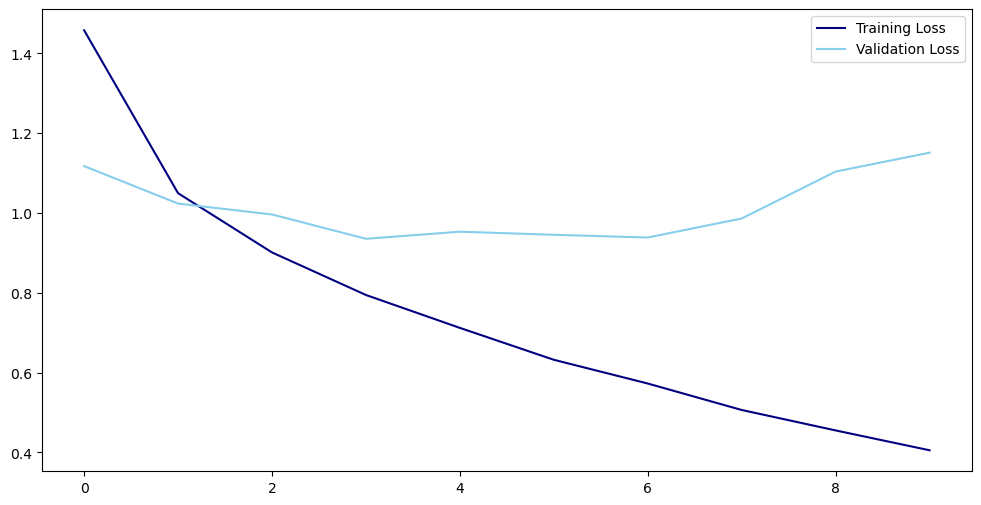

In [32]:
# Check out the plot of loss vs epoch. How's our model?
plt.figure(figsize=(12, 6))
plt.plot(history.history['loss'], c='navy', label='Training Loss')
plt.plot(history.history['val_loss'], c='skyblue', label='Validation Loss')
plt.legend();

# Summary
CNNs are cool! They're the first time we're able to _really_ work with image data. Parting thoughts from this lesson:
* Two fundamental truths of image recognition are that images are inherently **translation invariant** and **spatially hierarchical**.
    * Translation invariant = We still recognize things when they move over a little bit.
    * We recognize complex images as being made up of smaller features (edges, corners, etc)
* CNNs are engineered to incorporate these two fundamental truths.
* Generally the format of a CNN is as follows:
    * Convolutional layer.
    * MaxPool layer.
    * Repeat the above two steps, if desired.
    * Flatten the weights into a single vector.
    * A dense layer or two before the output.